# Recomendación colaborativa de películas: Análisis exploratorio

Ordenar películas para usuarios existentes de una muestra de MovieLens 32M.

Explora train cuando existe una partición de entrenamiento. En tareas descriptivas explora el catálogo preparado. Las cifras y comentarios se recalculan al ejecutar.

Consulta la [metodología](../docs/metodologia.md). Los reportes corresponden a la última ejecución de cada etapa.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("movielens_recommender")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from movielens_recommender.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Recomendación colaborativa de películas: eda

El análisis utiliza **127,245 registros de train**, con **0 valores ausentes**. La muestra de usuarios limita el alcance. Las valoraciones posteriores no participan en el ajuste.


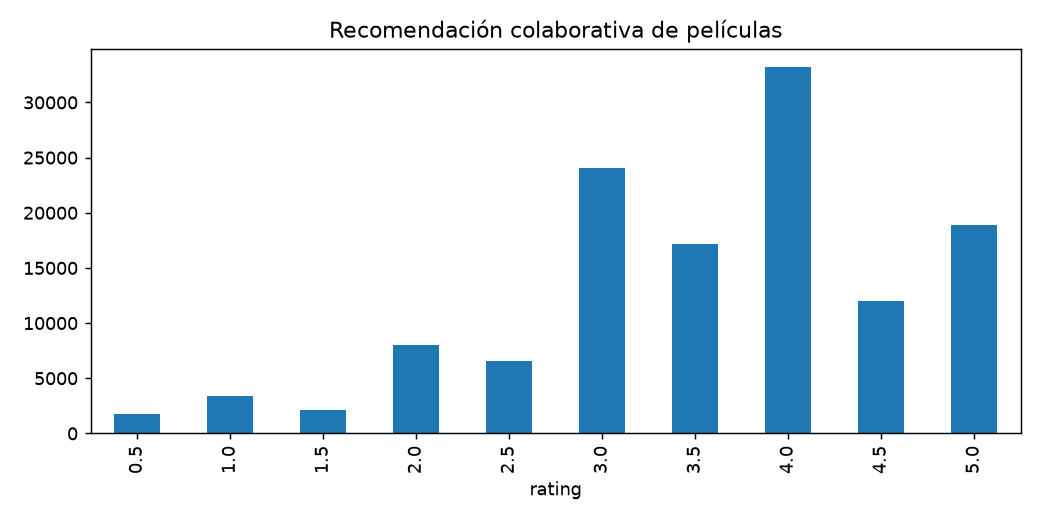

In [2]:
from movielens_recommender.flow import run_stage
metricas, comentario = run_stage(PROJECT_ROOT, "eda")
display(Markdown(comentario))
from IPython.display import Image
display(Image(filename=str(PROJECT_ROOT / "reports/eda/eda.png")))


## Alertas

Avisos agrupados con descripción y acción sugerida. Los errores no se ocultan; no registrar warnings no garantiza que el análisis sea válido.

In [ ]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/02_analisis_exploratorio.json")
from movielens_recommender.informe import generar_informe
generar_informe(PROJECT_ROOT)
